In [10]:
import duckdb

con = duckdb.connect("../olist.duckdb")

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

for name, file in files.items():
    con.execute(
        f"CREATE OR REPLACE TABLE {name} AS "
        f"SELECT * FROM read_csv_auto('../data/{file}')"
    )
    n = con.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
    print(f"{name}: {n:,} rows")

customers: 99,441 rows
geolocation: 1,000,163 rows
order_items: 112,650 rows
payments: 103,886 rows
reviews: 99,224 rows
orders: 99,441 rows
products: 32,951 rows
sellers: 3,095 rows
category_translation: 71 rows


In [11]:
con.sql("SELECT * FROM orders LIMIT 5").df()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [12]:
con.sql("DESCRIBE orders").df()

,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,order_status,VARCHAR,YES,None,None,None
3,order_purchase_timestamp,TIMESTAMP,YES,None,None,None
4,order_approved_at,TIMESTAMP,YES,None,None,None
5,order_delivered_carrier_date,TIMESTAMP,YES,None,None,None
6,order_delivered_customer_date,TIMESTAMP,YES,None,None,None
7,order_estimated_delivery_date,TIMESTAMP,YES,None,None,None


In [13]:
con.sql("""
SELECT order_status,
       COUNT(*) AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM orders
GROUP BY order_status
ORDER BY orders DESC
""").df()

,order_status,orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [14]:
con.sql("""
SELECT MIN(order_purchase_timestamp) AS first_order,
       MAX(order_purchase_timestamp) AS last_order,
       COUNT(*) AS total_rows,
       COUNT(DISTINCT order_id) AS unique_orders,
       COUNT(DISTINCT customer_id) AS unique_customer_ids
FROM orders
""").df()

,first_order,last_order,total_rows,unique_orders,unique_customer_ids
0,2016-09-04 21:15:19,2018-10-17 17:30:18,99441,99441,99441


In [15]:
con.sql("""
SELECT COUNT(*) AS total_rows,
       COUNT(DISTINCT customer_id) AS distinct_customer_id,
       COUNT(DISTINCT customer_unique_id) AS distinct_customer_unique_id
FROM customers
""").df()

,total_rows,distinct_customer_id,distinct_customer_unique_id
0,99441,99441,96096


In [16]:
con.sql("""
SELECT COUNT(*) AS total_orders,
       COUNT(*) - COUNT(order_approved_at) AS missing_approved,
       COUNT(*) - COUNT(order_delivered_carrier_date) AS missing_carrier_date,
       COUNT(*) - COUNT(order_delivered_customer_date) AS missing_delivery_date
FROM orders
""").df()

,total_orders,missing_approved,missing_carrier_date,missing_delivery_date
0,99441,160,1783,2965


In [17]:
con.sql("""
SELECT order_status,
       COUNT(*) AS orders,
       COUNT(*) - COUNT(order_delivered_customer_date) AS missing_delivery_date
FROM orders
GROUP BY order_status
ORDER BY orders DESC
""").df()

,order_status,orders,missing_delivery_date
0,delivered,96478,8
1,shipped,1107,1107
2,canceled,625,619
3,unavailable,609,609
4,invoiced,314,314
5,processing,301,301
6,created,5,5
7,approved,2,2


In [18]:
con.sql("""
SELECT DATE_TRUNC('month', order_purchase_timestamp) AS month,
       COUNT(*) AS orders
FROM orders
GROUP BY 1
ORDER BY 1
""").df()

,month,orders
0,2016-09-01,4
1,2016-10-01,324
2,2016-12-01,1
3,2017-01-01,800
4,2017-02-01,1780
5,2017-03-01,2682
6,2017-04-01,2404
7,2017-05-01,3700
8,2017-06-01,3245
9,2017-07-01,4026


In [19]:
con.sql("""
WITH per_customer AS (
    SELECT c.customer_unique_id,
           COUNT(DISTINCT o.order_id) AS orders
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    GROUP BY c.customer_unique_id
)
SELECT orders,
       COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM per_customer
GROUP BY orders
ORDER BY orders
""").df()

,orders,customers,pct
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4,30,0.03
4,5,8,0.01
5,6,6,0.01
6,7,3,0.00
7,9,1,0.00
8,17,1,0.00


In [20]:
con.sql("""
SELECT
  ROUND(AVG(epoch(order_approved_at) - epoch(order_purchase_timestamp)) / 3600, 1) AS avg_hours_purchase_to_approval,
  ROUND(AVG(epoch(order_delivered_carrier_date) - epoch(order_approved_at)) / 86400, 1) AS avg_days_approval_to_carrier,
  ROUND(AVG(epoch(order_delivered_customer_date) - epoch(order_delivered_carrier_date)) / 86400, 1) AS avg_days_carrier_to_customer,
  ROUND(AVG(epoch(order_delivered_customer_date) - epoch(order_purchase_timestamp)) / 86400, 1) AS avg_total_days
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
""").df()

,avg_hours_purchase_to_approval,avg_days_approval_to_carrier,avg_days_carrier_to_customer,avg_total_days
0,10.3,2.8,9.3,12.6


In [21]:
con.sql("""
SELECT COUNT(*) AS delivered_orders,
       SUM(CASE WHEN order_delivered_customer_date > order_estimated_delivery_date THEN 1 ELSE 0 END) AS late_orders,
       ROUND(100.0 * SUM(CASE WHEN order_delivered_customer_date > order_estimated_delivery_date THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_late
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
""").df()

,delivered_orders,late_orders,pct_late
0,96470,7826.0,8.11


In [22]:
con.sql("""
SELECT DATE_TRUNC('month', order_purchase_timestamp) AS month,
       COUNT(*) AS delivered_orders,
       ROUND(100.0 * AVG(CASE WHEN order_delivered_customer_date > order_estimated_delivery_date THEN 1 ELSE 0 END), 2) AS pct_late
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp <  '2018-09-01'
GROUP BY 1
ORDER BY 1
""").df()

,month,delivered_orders,pct_late
0,2017-01-01,750,3.07
1,2017-02-01,1653,3.21
2,2017-03-01,2546,5.58
3,2017-04-01,2303,7.86
4,2017-05-01,3545,3.61
5,2017-06-01,3135,3.86
6,2017-07-01,3872,3.43
7,2017-08-01,4193,3.32
8,2017-09-01,4150,5.20
9,2017-10-01,4478,5.29


In [23]:
con.sql("""
SELECT COUNT(*) AS total_rows,
       COUNT(DISTINCT order_id) AS distinct_orders
FROM reviews
""").df()

,total_rows,distinct_orders
0,99224,98673


In [24]:
con.sql("""
SELECT review_score,
       COUNT(*) AS reviews,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM reviews
GROUP BY review_score
ORDER BY review_score
""").df()

,review_score,reviews,pct
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


In [25]:
con.sql("""
WITH order_reviews AS (
    SELECT order_id, AVG(review_score) AS score
    FROM reviews
    GROUP BY order_id
),
delivered AS (
    SELECT order_id,
           CASE WHEN order_delivered_customer_date > order_estimated_delivery_date
                THEN 'late' ELSE 'on_time' END AS delivery_status
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
)
SELECT d.delivery_status,
       COUNT(*) AS orders,
       ROUND(AVG(r.score), 2) AS avg_review_score
FROM delivered d
JOIN order_reviews r ON d.order_id = r.order_id
GROUP BY d.delivery_status
""").df()

,delivery_status,orders,avg_review_score
0,late,7661,2.57
1,on_time,88163,4.29


In [26]:
con.sql("""
WITH order_reviews AS (
    SELECT order_id, AVG(review_score) AS score
    FROM reviews
    GROUP BY order_id
),
delivered AS (
    SELECT order_id,
           (epoch(order_delivered_customer_date) - epoch(order_estimated_delivery_date)) / 86400 AS days_late
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
)
SELECT CASE WHEN days_late <= 0 THEN '1_on_time'
            WHEN days_late <= 3 THEN '2_1-3_days_late'
            WHEN days_late <= 7 THEN '3_4-7_days_late'
            ELSE '4_8plus_days_late' END AS lateness,
       COUNT(*) AS orders,
       ROUND(AVG(r.score), 2) AS avg_review_score
FROM delivered d
JOIN order_reviews r ON d.order_id = r.order_id
GROUP BY 1
ORDER BY 1
""").df()

,lateness,orders,avg_review_score
0,1_on_time,88163,4.29
1,2_1-3_days_late,2636,3.77
2,3_4-7_days_late,1773,2.32
3,4_8plus_days_late,3252,1.73


In [27]:
con.sql("""
WITH order_reviews AS (
    SELECT order_id, AVG(review_score) AS score
    FROM reviews
    GROUP BY order_id
),
delivered AS (
    SELECT order_id,
           CASE WHEN order_delivered_customer_date > order_estimated_delivery_date
                THEN 'late' ELSE 'on_time' END AS delivery_status
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
)
SELECT d.delivery_status,
       COUNT(*) AS orders,
       ROUND(100.0 * AVG(CASE WHEN r.score <= 2 THEN 1 ELSE 0 END), 2) AS pct_low_reviews
FROM delivered d
JOIN order_reviews r ON d.order_id = r.order_id
GROUP BY d.delivery_status
""").df()

,delivery_status,orders,pct_low_reviews
0,on_time,88163,9.19
1,late,7661,53.99


In [28]:
con.sql("""
WITH order_reviews AS (
    SELECT order_id, AVG(review_score) AS score
    FROM reviews
    GROUP BY order_id
),
delivered AS (
    SELECT order_id,
           CASE WHEN order_delivered_customer_date > order_estimated_delivery_date
                THEN 'late' ELSE 'on_time' END AS delivery_status
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
)
SELECT COUNT(*) AS low_review_orders,
       SUM(CASE WHEN d.delivery_status = 'late' THEN 1 ELSE 0 END) AS late_among_them,
       ROUND(100.0 * SUM(CASE WHEN d.delivery_status = 'late' THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_late_among_low
FROM delivered d
JOIN order_reviews r ON d.order_id = r.order_id
WHERE r.score <= 2
""").df()

,low_review_orders,late_among_them,pct_late_among_low
0,12236,4136.0,33.8


In [29]:
con.sql("""
SELECT c.customer_state,
       COUNT(*) AS delivered_orders,
       ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                              THEN 1 ELSE 0 END), 2) AS pct_late
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
HAVING COUNT(*) >= 500
ORDER BY pct_late DESC
LIMIT 10
""").df()

,customer_state,delivered_orders,pct_late
0,MA,717,19.67
1,CE,1279,15.32
2,BA,3256,14.04
3,RJ,12350,13.47
4,PA,946,12.37
5,ES,1995,12.23
6,MS,701,11.55
7,PB,517,11.03
8,PE,1593,10.80
9,SC,3546,9.76


In [30]:
con.sql("""
SELECT c.customer_state,
       COUNT(*) AS delivered_orders,
       SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 1 ELSE 0 END) AS late_orders,
       ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                              THEN 1 ELSE 0 END), 2) AS pct_late
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY late_orders DESC
LIMIT 10
""").df()

,customer_state,delivered_orders,late_orders,pct_late
0,SP,40494,2387.0,5.89
1,RJ,12350,1664.0,13.47
2,MG,11354,637.0,5.61
3,BA,3256,457.0,14.04
4,RS,5344,382.0,7.15
5,SC,3546,346.0,9.76
6,PR,4923,246.0,5.00
7,ES,1995,244.0,12.23
8,CE,1279,196.0,15.32
9,PE,1593,172.0,10.80


In [31]:
con.sql("""
WITH orders_c AS (
    SELECT c.customer_unique_id,
           o.order_id,
           o.order_status,
           o.order_purchase_timestamp,
           o.order_delivered_customer_date,
           o.order_estimated_delivery_date
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY order_purchase_timestamp) AS rn,
           COUNT(*) OVER (PARTITION BY customer_unique_id) AS total_orders
    FROM orders_c
)
SELECT CASE WHEN order_delivered_customer_date > order_estimated_delivery_date
            THEN 'late' ELSE 'on_time' END AS first_order_delivery,
       COUNT(*) AS customers,
       ROUND(100.0 * AVG(CASE WHEN total_orders > 1 THEN 1 ELSE 0 END), 2) AS repeat_rate_pct
FROM ranked
WHERE rn = 1
  AND order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp <  '2018-01-01'
GROUP BY 1
""").df()

,first_order_delivery,customers,repeat_rate_pct
0,on_time,39307,4.3
1,late,2795,2.9


In [32]:
df = con.sql("""
WITH orders_c AS (
    SELECT c.customer_unique_id,
           o.order_id,
           o.order_status,
           o.order_purchase_timestamp,
           o.order_delivered_customer_date,
           o.order_estimated_delivery_date
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY order_purchase_timestamp) AS rn,
           COUNT(*) OVER (PARTITION BY customer_unique_id) AS total_orders
    FROM orders_c
)
SELECT CASE WHEN order_delivered_customer_date > order_estimated_delivery_date
            THEN 'late' ELSE 'on_time' END AS first_order_delivery,
       COUNT(*) AS customers,
       SUM(CASE WHEN total_orders > 1 THEN 1 ELSE 0 END) AS repeaters
FROM ranked
WHERE rn = 1
  AND order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp <  '2018-01-01'
GROUP BY 1
""").df()
df

,first_order_delivery,customers,repeaters
0,on_time,39304,1688.0
1,late,2795,81.0


In [33]:
import math
from statsmodels.stats.proportion import proportions_ztest

late = df[df.first_order_delivery == "late"].iloc[0]
ontime = df[df.first_order_delivery == "on_time"].iloc[0]

count = [int(late.repeaters), int(ontime.repeaters)]
nobs = [int(late.customers), int(ontime.customers)]

stat, pval = proportions_ztest(count, nobs)
print(f"z = {stat:.2f}, p-value = {pval:.4f}")

p1, p2 = count[0] / nobs[0], count[1] / nobs[1]
diff = p1 - p2
se = math.sqrt(p1 * (1 - p1) / nobs[0] + p2 * (1 - p2) / nobs[1])
low, high = diff - 1.96 * se, diff + 1.96 * se

print(f"Repeat rate: late = {p1:.2%}, on-time = {p2:.2%}")
print(f"Difference = {diff:.2%} points, 95% CI = [{low:.2%}, {high:.2%}]")

z = -3.56, p-value = 0.0004
Repeat rate: late = 2.90%, on-time = 4.29%
Difference = -1.40% points, 95% CI = [-2.05%, -0.74%]


In [34]:
cohort = con.sql("""
WITH orders_c AS (
    SELECT c.customer_unique_id,
           DATE_TRUNC('month', o.order_purchase_timestamp) AS order_month
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
),
first_month AS (
    SELECT customer_unique_id, MIN(order_month) AS cohort_month
    FROM orders_c
    GROUP BY 1
),
activity AS (
    SELECT f.cohort_month,
           date_diff('month', f.cohort_month, o.order_month) AS month_offset,
           COUNT(DISTINCT o.customer_unique_id) AS active_customers
    FROM orders_c o
    JOIN first_month f USING (customer_unique_id)
    GROUP BY 1, 2
),
cohort_size AS (
    SELECT cohort_month, COUNT(*) AS size
    FROM first_month
    GROUP BY 1
)
SELECT a.cohort_month,
       s.size,
       a.month_offset,
       a.active_customers,
       ROUND(100.0 * a.active_customers / s.size, 2) AS retention_pct
FROM activity a
JOIN cohort_size s USING (cohort_month)
WHERE a.cohort_month >= '2017-01-01'
  AND a.cohort_month <  '2018-09-01'
  AND a.month_offset BETWEEN 0 AND 6
ORDER BY 1, 3
""").df()

matrix = cohort.pivot(index="cohort_month", columns="month_offset", values="retention_pct")
matrix

month_offset,0,1,2,3,4,5,6
cohort_month,,,,,,,
2017-01-01,100.0,0.40,0.27,0.13,0.40,0.13,0.40
2017-02-01,100.0,0.24,0.30,0.12,0.41,0.12,0.24
2017-03-01,100.0,0.51,0.35,0.39,0.35,0.16,0.16
2017-04-01,100.0,0.60,0.22,0.17,0.30,0.26,0.34
2017-05-01,100.0,0.48,0.48,0.40,0.31,0.34,0.42
2017-06-01,100.0,0.45,0.35,0.39,0.26,0.39,0.35
2017-07-01,100.0,0.52,0.34,0.24,0.29,0.21,0.31
2017-08-01,100.0,0.68,0.34,0.27,0.36,0.53,0.29
2017-09-01,100.0,0.69,0.54,0.29,0.44,0.22,0.22


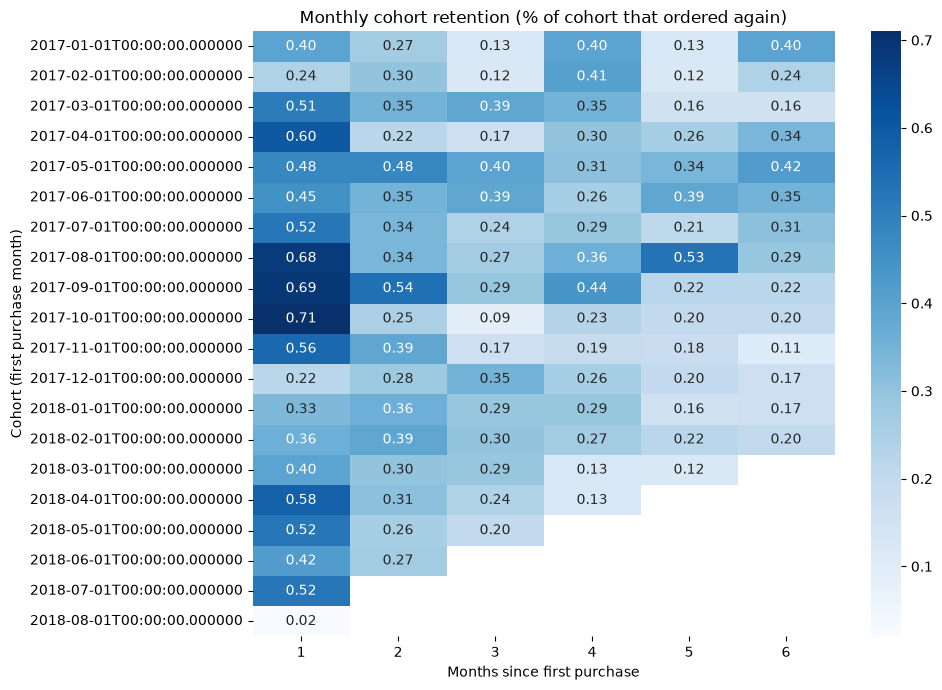

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
sns.heatmap(matrix.iloc[:, 1:], annot=True, fmt=".2f", cmap="Blues")
plt.title("Monthly cohort retention (% of cohort that ordered again)")
plt.xlabel("Months since first purchase")
plt.ylabel("Cohort (first purchase month)")
plt.tight_layout()
plt.show()

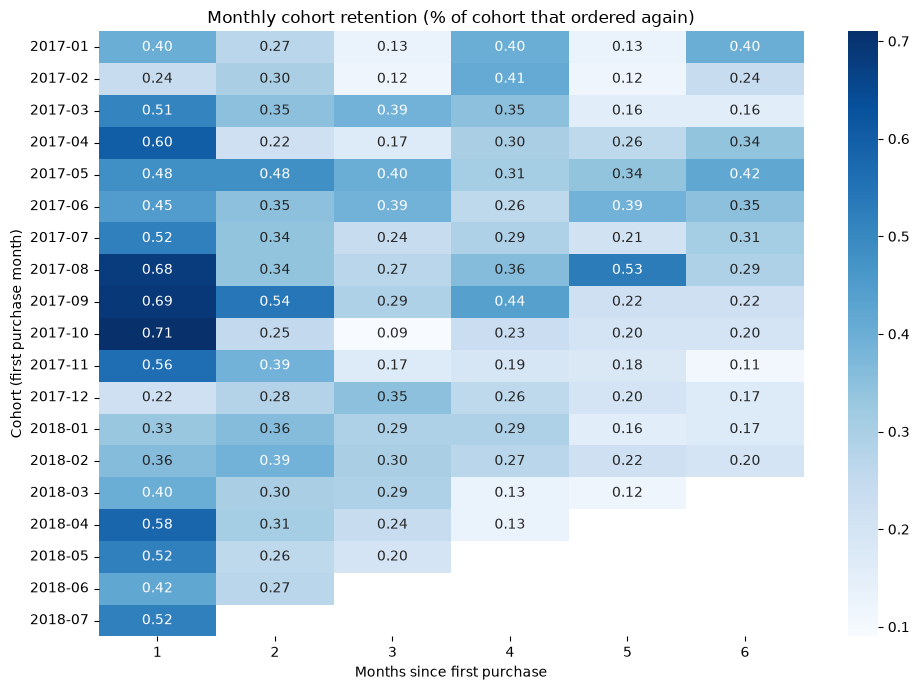

In [36]:
import os
import pandas as pd

matrix.index = pd.to_datetime(matrix.index).strftime("%Y-%m")
matrix_clean = matrix.drop(index="2018-08")

os.makedirs("../images", exist_ok=True)

plt.figure(figsize=(10, 7))
sns.heatmap(matrix_clean.iloc[:, 1:], annot=True, fmt=".2f", cmap="Blues")
plt.title("Monthly cohort retention (% of cohort that ordered again)")
plt.xlabel("Months since first purchase")
plt.ylabel("Cohort (first purchase month)")
plt.tight_layout()
plt.savefig("../images/cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
con.sql("""
SELECT COUNT(*) AS total_rows,
       COUNT(DISTINCT order_id) AS distinct_orders,
       ROUND(AVG(payment_value), 2) AS avg_payment_row
FROM payments
""").df()

,total_rows,distinct_orders,avg_payment_row
0,103886,99440,154.1


In [38]:
con.sql("""
WITH order_values AS (
    SELECT order_id, SUM(payment_value) AS order_value
    FROM payments
    GROUP BY order_id
)
SELECT DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
       COUNT(*) AS orders,
       ROUND(SUM(v.order_value), 0) AS revenue,
       ROUND(AVG(v.order_value), 2) AS avg_order_value
FROM orders o
JOIN order_values v ON o.order_id = v.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY 1
ORDER BY 1
""").df()

,month,orders,revenue,avg_order_value
0,2017-01-01,750,127546.0,170.06
1,2017-02-01,1653,271299.0,164.13
2,2017-03-01,2546,414369.0,162.75
3,2017-04-01,2303,390952.0,169.76
4,2017-05-01,3546,567067.0,159.92
5,2017-06-01,3135,490226.0,156.37
6,2017-07-01,3872,566404.0,146.28
7,2017-08-01,4193,646001.0,154.07
8,2017-09-01,4150,701170.0,168.96
9,2017-10-01,4478,751140.0,167.74


In [39]:
con.sql("""
SELECT COALESCE(t.product_category_name_english, p.product_category_name) AS category,
       COUNT(DISTINCT oi.order_id) AS orders,
       ROUND(SUM(oi.price), 0) AS revenue,
       ROUND(AVG(oi.price), 2) AS avg_item_price
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
GROUP BY 1
ORDER BY revenue DESC
LIMIT 10
""").df()

,category,orders,revenue,avg_item_price
0,health_beauty,8836,1258681.0,130.16
1,watches_gifts,5624,1205006.0,201.14
2,bed_bath_table,9417,1036989.0,93.30
3,sports_leisure,7720,988049.0,114.34
4,computers_accessories,6689,911954.0,116.51
5,furniture_decor,6449,729762.0,87.56
6,cool_stuff,3632,635291.0,167.36
7,housewares,5884,632249.0,90.79
8,auto,3897,592720.0,139.96
9,garden_tools,3518,485256.0,111.63


In [40]:
orders_df = con.sql("""
WITH order_values AS (
    SELECT order_id, SUM(payment_value) AS order_value
    FROM payments
    GROUP BY order_id
)
SELECT v.order_value
FROM orders o
JOIN order_values v ON o.order_id = v.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""").df()

print(orders_df.order_value.describe())
print("skew:", round(orders_df.order_value.skew(), 2))

count    96211.000000
mean       159.814111
std        218.881635
min          9.590000
25%         61.880000
50%        105.280000
75%        176.260000
max      13664.080000
Name: order_value, dtype: float64
skew: 9.38


In [41]:
import math
from statsmodels.stats.power import TTestIndPower

mean = orders_df.order_value.mean()
std = orders_df.order_value.std()

for lift in [0.02, 0.05, 0.10]:
    d = (mean * lift) / std
    n = TTestIndPower().solve_power(effect_size=d, alpha=0.05, power=0.8,
                                    ratio=1.0, alternative="two-sided")
    print(f"{lift:.0%} lift (+R${mean * lift:.2f}): need about {math.ceil(n):,} orders per group")

2% lift (+R$3.20): need about 73,616 orders per group
5% lift (+R$7.99): need about 11,780 orders per group
10% lift (+R$15.98): need about 2,946 orders per group


In [42]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
values = orders_df.order_value.values
half = len(values) // 2

false_positives = 0
for _ in range(1000):
    shuffled = rng.permutation(values)
    _, p = stats.ttest_ind(shuffled[:half], shuffled[half:], equal_var=False)
    false_positives += p < 0.05

print(f"A/A test false positive rate: {false_positives / 1000:.1%}")

A/A test false positive rate: 4.1%


In [43]:
for n in [500, 1000, 2000, 5000]:
    hits = 0
    for _ in range(1000):
        s = rng.choice(values, size=2 * n, replace=False)
        a, b = s[:n], s[n:] * 1.05
        _, p = stats.ttest_ind(a, b, equal_var=False)
        hits += p < 0.05
    print(f"n per group = {n:,}: power is about {hits / 1000:.0%}")

n per group = 500: power is about 8%
n per group = 1,000: power is about 13%
n per group = 2,000: power is about 22%
n per group = 5,000: power is about 42%


In [44]:
cap = orders_df.order_value.quantile(0.99)
capped = orders_df.order_value.clip(upper=cap)

mean_c, std_c = capped.mean(), capped.std()
d = (mean_c * 0.05) / std_c
n = TTestIndPower().solve_power(effect_size=d, alpha=0.05, power=0.8,
                                ratio=1.0, alternative="two-sided")

print(f"99th percentile cap: R${cap:.2f}")
print(f"Std before: R${std:.2f}  |  after cap: R${std_c:.2f}")
print(f"5% lift now needs about {math.ceil(n):,} orders per group (was 11,780)")

99th percentile cap: R$1053.61
Std before: R$218.88  |  after cap: R$163.82
5% lift now needs about 7,133 orders per group (was 11,780)


In [45]:
import sys
print(sys.executable)

d:\PROJECT\Olist Analytics\.venv\Scripts\python.exe


In [46]:
import os
import pandas as pd

os.makedirs("../exports", exist_ok=True)

# 1. Monthly summary
con.execute("""
COPY (
    WITH order_values AS (
        SELECT order_id, SUM(payment_value) AS order_value
        FROM payments
        GROUP BY order_id
    )
    SELECT DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
           COUNT(*) AS orders,
           ROUND(SUM(v.order_value), 2) AS revenue,
           ROUND(AVG(v.order_value), 2) AS avg_order_value,
           ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                                  THEN 1 ELSE 0 END), 2) AS pct_late
    FROM orders o
    JOIN order_values v ON o.order_id = v.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
    GROUP BY 1
    ORDER BY 1
) TO '../exports/monthly_summary.csv' (HEADER, DELIMITER ',')
""")

# 2. Delivery performance by state
con.execute("""
COPY (
    SELECT c.customer_state AS state,
           COUNT(*) AS delivered_orders,
           SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                    THEN 1 ELSE 0 END) AS late_orders,
           ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                                  THEN 1 ELSE 0 END), 2) AS pct_late,
           ROUND(AVG((epoch(o.order_delivered_customer_date) - epoch(o.order_purchase_timestamp)) / 86400), 1) AS avg_delivery_days
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY 1
    ORDER BY late_orders DESC
) TO '../exports/state_delivery.csv' (HEADER, DELIMITER ',')
""")

# 3. Lateness vs review score
con.execute("""
COPY (
    WITH order_reviews AS (
        SELECT order_id, AVG(review_score) AS score
        FROM reviews
        GROUP BY order_id
    ),
    delivered AS (
        SELECT order_id,
               (epoch(order_delivered_customer_date) - epoch(order_estimated_delivery_date)) / 86400 AS days_late
        FROM orders
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
    )
    SELECT CASE WHEN days_late <= 0 THEN '1_on_time'
                WHEN days_late <= 3 THEN '2_1-3_days_late'
                WHEN days_late <= 7 THEN '3_4-7_days_late'
                ELSE '4_8plus_days_late' END AS lateness,
           COUNT(*) AS orders,
           ROUND(AVG(r.score), 2) AS avg_review_score
    FROM delivered d
    JOIN order_reviews r ON d.order_id = r.order_id
    GROUP BY 1
    ORDER BY 1
) TO '../exports/lateness_vs_reviews.csv' (HEADER, DELIMITER ',')
""")

# 4. Top product categories
con.execute("""
COPY (
    SELECT COALESCE(t.product_category_name_english, p.product_category_name) AS category,
           COUNT(DISTINCT oi.order_id) AS orders,
           ROUND(SUM(oi.price), 0) AS revenue,
           ROUND(AVG(oi.price), 2) AS avg_item_price
    FROM order_items oi
    JOIN products p ON oi.product_id = p.product_id
    LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
    GROUP BY 1
    ORDER BY revenue DESC
    LIMIT 15
) TO '../exports/category_revenue.csv' (HEADER, DELIMITER ',')
""")

# 5. Cohort retention (long format, excluding the unreliable Aug 2018 cohort)
cohort_export = cohort.copy()
cohort_export["cohort_month"] = pd.to_datetime(cohort_export["cohort_month"])
cohort_export = cohort_export[cohort_export["cohort_month"] < "2018-08-01"]
cohort_export["cohort_month"] = cohort_export["cohort_month"].dt.strftime("%Y-%m")
cohort_export.to_csv("../exports/cohort_retention.csv", index=False)

print("Exported:", sorted(os.listdir("../exports")))

Exported: ['category_revenue.csv', 'cohort_retention.csv', 'lateness_vs_reviews.csv', 'monthly_summary.csv', 'state_delivery.csv']


In [47]:
pd.read_csv("../exports/monthly_summary.csv").head()

,month,orders,revenue,avg_order_value,pct_late
0,2017-01-01 00:00:00,750,127545.67,170.06,3.07
1,2017-02-01 00:00:00,1653,271298.65,164.13,3.21
2,2017-03-01 00:00:00,2546,414369.39,162.75,5.58
3,2017-04-01 00:00:00,2303,390952.18,169.76,7.86
4,2017-05-01 00:00:00,3545,566872.73,159.91,3.61


In [48]:
import duckdb
con = duckdb.connect("../olist.duckdb")